# 第15章：异常排序与阈值

**教师参考｜全书深化稿**

## 背景与数据
正常参考、正常查询和20条远处异常均由固定随机过程生成，注入位置已知。

## 本次要回答的问题
分别计算异常分数、阈值、候选数、误报和检出；核对LOF局部密度例子。

先写下预判，再运行，最后用实际结果解释；不需要结果符合预期才算成功。

In [1]:
from pathlib import Path
import os, sys
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "experiments/common.py").exists()
             and (p / "main.tex").exists()), None)
if root is None:
    raise RuntimeError("Open this notebook inside the extracted textbook project.")
sys.path.insert(0, str(root / "experiments"))
print("Project:", root)


Project: /mnt/data/book_v3


## 可检查的完整实验代码

下方与对应`experiments`脚本一致。共享的`common.py`只提供固定数据划分、保存表图和绘图设置；模型、目标、参数及比较规则在此明确写出。阅读函数后，再运行下一单元执行实验。

In [2]:
"""Chapter 15: scores are rankings; thresholds require evaluation and a reference set."""
import numpy as np
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import precision_score,recall_score,average_precision_score
from common import *

def run():
    rng=np.random.default_rng(150)
    reference=rng.normal(size=(400,2))
    normal=rng.normal(size=(200,2));anomaly=rng.uniform(4,7,size=(20,2));X=np.vstack([normal,anomaly]);y=np.r_[np.zeros(200,int),np.ones(20,int)]
    m=IsolationForest(n_estimators=200,contamination='auto',random_state=42).fit(reference)
    refscore=-m.score_samples(reference);score=-m.score_samples(X);rows=[]
    for q in [.90,.95,.99]:
        threshold=np.quantile(refscore,q);p=score>threshold
        rows.append({'reference_quantile':q,'threshold':threshold,'candidates':int(p.sum()),'precision':precision_score(y,p,zero_division=0),'recall':recall_score(y,p,zero_division=0),'normal_false_positive_rate':float(p[:200].mean())})
    df=table('ch15_thresholds',rows);show_result(df)
    table('ch15_candidates',{'row_id':np.arange(len(y)),'x1':X[:,0],'x2':X[:,1],'injected_label':y,'anomaly_score':score})
    np.savez(DATA/'synthetic_anomaly_reference.npz',reference=reference,X=X,y=y)
    dump('ch15_ranking',{'average_precision':average_precision_score(y,score),'n_reference':len(reference),'n_query':len(y)})
    plt.figure(figsize=(6.4,4));plt.hist(score[y==0],bins=20,alpha=.6,label='normal queries');plt.hist(score[y==1],bins=15,alpha=.6,label='injected queries');plt.xlabel('负 score_samples：越大越异常');plt.ylabel('记录数');plt.legend();figure('v3_ch15_scores')
    # A local-density example has different meanings from a global score.
    dense=rng.normal(0,.15,(120,2));sparse=rng.normal([3,0],[.7,.7],(120,2));P=np.vstack([dense,sparse,[[.8,0]]])
    lof=LocalOutlierFactor(n_neighbors=20).fit(P);s=-lof.negative_outlier_factor_
    table('ch15_local',{'row_id':np.arange(len(P)),'x1':P[:,0],'x2':P[:,1],'LOF':s})
    plt.figure(figsize=(6.4,4));plt.scatter(P[:,0],P[:,1],s=15+20*np.clip(s-1,0,5));plt.xlabel('人工坐标 x1');plt.ylabel('人工坐标 x2');figure('v3_ch15_local_density')

In [3]:
result = run()
if result is not None:
    print(result)

 reference_quantile  threshold  candidates  precision  recall  normal_false_positive_rate
               0.90   0.550333          40   0.500000     1.0                       0.100
               0.95   0.592046          29   0.689655     1.0                       0.045
               0.99   0.668462          20   1.000000     1.0                       0.000


## 检查结果文件与图

下面显示该实验保存的图；所有坐标、样本与数值条件应与正文一致。数据表保存在`results/`。修改代码后，请另存结果或注明变化，不把新配置的输出与正文旧数值混用。

v3_ch15_local_density.png


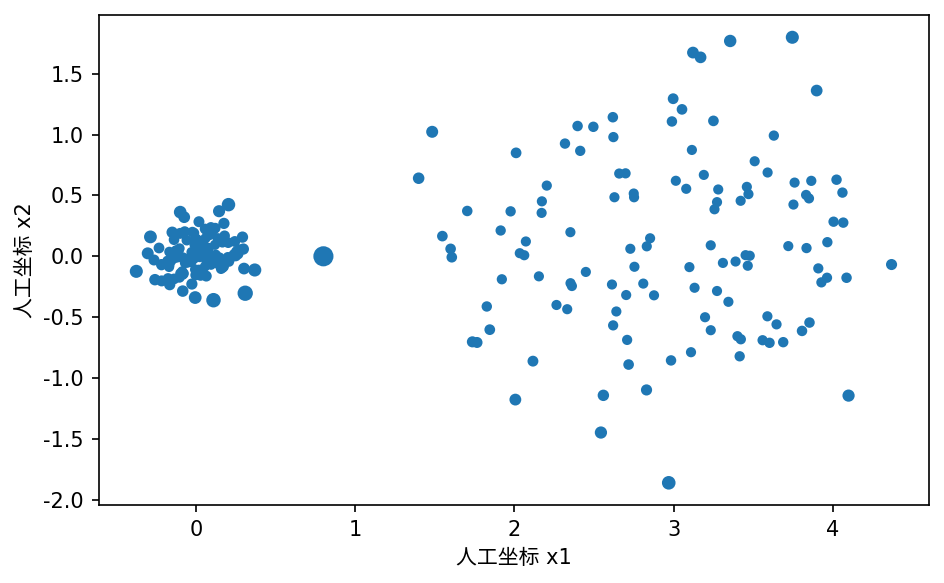

v3_ch15_scores.png


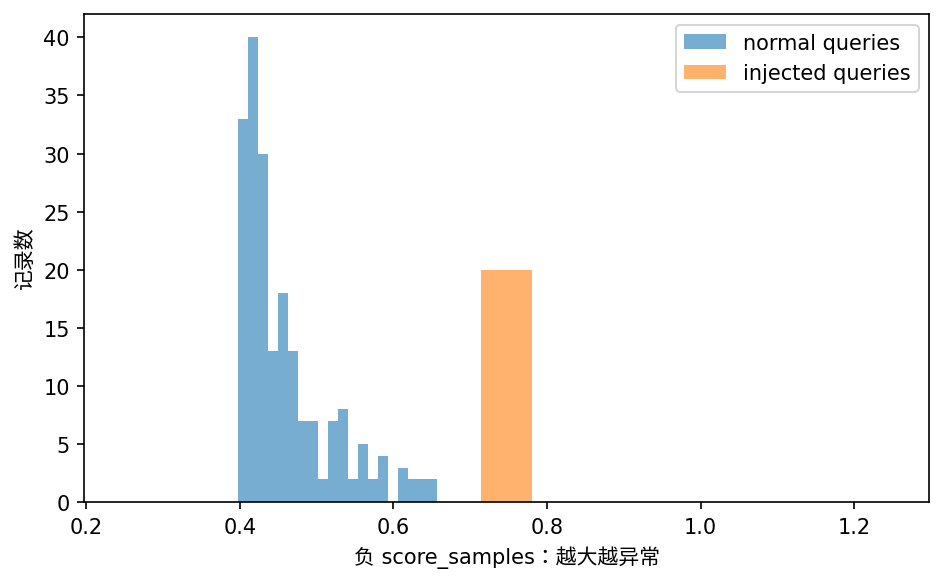

In [4]:
from IPython.display import display, Image
files = sorted((root / "figures").glob("v3_ch15_*.png"))
for path in files:
    print(path.name)
    display(Image(filename=str(path), width=720))
if not files:
    print("This experiment uses tables rather than a new figure.")

## 教师解释与核对

远处人工异常易被找出，不能据此声称真实异常检出率100%。阈值预算不是自然界异常比例。

完整手算解答见`teacher_manual.pdf`。如果结果与这里的参考不同，先检查数据版本、划分、软件环境、目标归一化和随机状态，不要求学生人为调成相同分数。

**评分顺序：**问题与字段角色、数据划分、算法机制、实际结果分析、证据边界。代码能运行但无法说明一项输出的含义，不算完成理解目标。